# Mouche — le modèle de Soneira-Peebles **3D** correspondant

**D'où l'on vient.** Le notebook [`05`](05_fly_2pcf.ipynb) a mesuré la 2PCF des
238 909 noyaux de neurones de la drosophile : une loi de puissance propre sur
1.8 décade, ξ(r) = (r/r₀)^(−γ) avec **γ = 1.02 ± 0.04** et r₀ ≈ 20 µm, soit une
dimension de corrélation **D = 3 − γ = 1.98**. Il se terminait sur une liste de
courses : pour fabriquer le modèle de Soneira-Peebles correspondant, il faudra
`λ = η^(1/(3−γ))` et tirer les sous-amas dans des **sphères**. Ce notebook fait
ce travail, et le vérifie.

**Une remarque qui remet les choses à l'endroit.** Le modèle de Soneira &
Peebles (*ApJ* 1978, `doc/`) est **né en 3D**, pour les galaxies. Ce sont les
notebooks 01-04 — des cartes — qui en utilisent une spécialisation plane. Ce
notebook ne « généralise » donc pas le modèle : il lui rend sa dimension
d'origine, sur un objet qui n'est plus un catalogue de galaxies mais un cerveau.

**Ce qui change par rapport au code 2D du repo.** Comme au notebook 05, le
danger n'est pas que le code plante — c'est qu'il tourne.

| Ce que fait le code 2D | Ce que ça donne en 3D | Ce qu'on écrit ici |
|---|---|---|
| `l = eta**(1/(2-gamma))` | λ trop grand ⇒ D = ln η/ln λ trop petite : la fractale est **trop creuse**, dès le premier niveau | `lambda_of_gamma(eta, gamma, dim=3)` |
| enfants tirés dans un **disque** `(r cosθ, r sinθ)` | le nuage est plat : ce n'est pas une fractale de ℝ³ | tirage dans la **boule**, `sample_in_ball` |
| `r = R·u` (u uniforme) | même en 3D, ce n'est **pas** uniforme dans la boule (densité en r^(1−d)) | `r = R·u^(1/d)` (§ 4 chiffre l'écart) |
| `check_inside` relance **l'arbre entier** tant qu'un point sort du domaine | ne se termine jamais à η^L ~ 10⁵ points | rejet **enfant par enfant** |
| `L = int(log(N)/log(eta))` | couple la profondeur au nombre de points, donc la **portée** de la loi de puissance à N | L fixé par la portée, effectif ajusté après coup |
| `fit_2pcf` borné à γ ≤ 1.95 | encode D > 0 **en 2D** | borne à `dim`, comme au notebook 05 |

Les fonctions ajoutées en fin de [`src/sp_helpers.py`](../src/sp_helpers.py)
(`lambda_of_gamma`, `sample_in_ball`, `inside_hull`, `soneira_peebles_nd`)
reprennent la définition du modèle sans ces six hypothèses ; l'estimateur de la
2PCF, lui, est celui du notebook 05, inchangé.

**Plan.** (1) ce que le 05 a laissé · (2) le modèle, et le domaine · (3) la
relation λ ↔ γ vérifiée **sans** domaine · (4) l'estimateur et la loi radiale ·
(5) la profondeur L · (6) le fond aléatoire et le balayage sur η · (7) η est-il
identifiable ? · (8) le modèle retenu · (9) la distribution des distances
(Kullback-Leibler) · (10) à quoi ça ressemble · (11) limites · (12) sauvegarde ·
(13) bilan.

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, cKDTree
from scipy.optimize import curve_fit

ROOT = Path.cwd().resolve().parent           # racine fake_world_paper_july_2026/
sys.path.insert(0, str(ROOT / "src"))
import methods_two_point_correlation as mtpc
import save_load_pickle as slp
import sp_helpers as sph

# Palette Okabe-Ito, cohérente avec les notebooks 01-06
C = {"data": "#000000", "fly": "#0072B2", "sp": "#D55E00", "mix": "#009E73",
     "random": "#999999", "warn": "#CC79A7", "alt": "#56B4E9"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10, "axes.axisbelow": True})

SEED  = 42
NM    = 1e3                                  # 1 µm = 1000 nm
CACHE = ROOT / "out" / "05bis_cache"
CACHE.mkdir(parents=True, exist_ok=True)
print("cache :", CACHE)

cache : out/05bis_cache


## 1. Ce que le notebook 05 a laissé

Le pickle `out/fly/fly_2pcf_*` a été écrit pour être relu ici : il porte les
clés attendues par `fit_Soneira_Peebles` (`r_edges`, `xi`, `fit_SP`,
`clustering`, `distance_distribution`, `number_points`) **plus** les deux que
le passage en 3D impose — `dim = 3`, qui dit quelle dimension mettre dans
λ = η^(1/(dim−γ)), et `hull_points`, les 439 sommets de l'enveloppe convexe
3D qui tient lieu de domaine.

Trois choses en sortent et ne seront plus rediscutées :

- **γ = 1.022** et r₀ = 19.5 µm, la loi de puissance à reproduire ;
- **N = 238 909**, le nombre de points que le modèle devra fournir ;
- **η ∈ {2, 3, 5, 4, 6}**, les cinq nombres de sous-amas que le score de
  silhouette a retenus (§ 9 du notebook 05), classés du meilleur au moins bon.

In [2]:
PKL = ROOT / "out" / "fly" / "fly_2pcf_4_20000_8_20000_21"
d   = slp.load_results(PKL)

hull          = ConvexHull(d["hull_points"])
gamma_d, r0_d = d["fit_SP"]
N             = d["number_points"]
r_edges, r_c  = d["r_edges"], d["r_centers"]
xi_data, err_data = d["xi"].mean(axis=0), d["xi"].std(axis=0)
l_cluster     = d["clustering"]
prm           = d["params"]
rmin_d, rmax_d = prm["rmin"], prm["rmax"]
Nr_prime, N_run, Nsample = prm["Nr_prime"], prm["N_run"], prm["Nsample"]

print(f"dim = {d['dim']}  |  N = {N:,} points  |  γ = {gamma_d:.3f}  |  "
      f"r0 = {r0_d/NM:.1f} µm".replace(",", " "))
print(f"domaine : enveloppe convexe 3D, {len(hull.vertices)} sommets, "
      f"V = {hull.volume/NM**3:.3e} µm³")
print(f"bins : {len(r_c)} de {rmin_d/NM:.2f} à {rmax_d/NM:.0f} µm (log)")
print(f"η candidats (silhouette, décroissant) : {l_cluster}")

dim = 3  |  N = 238 909 points  |  γ = 1.022  |  r0 = 19.5 µm
domaine : enveloppe convexe 3D, 439 sommets, V = 3.930e+07 µm³
bins : 20 de 1.96 à 331 µm (log)
η candidats (silhouette, décroissant) : [2, 3, 5, 4, 6]


## 2. Le modèle, et ce que le domaine en fait

### La définition

On part d'une graine ; à chaque niveau i, **chaque** point engendre η enfants
tirés uniformément dans la **boule** de rayon R/λ^i qui l'entoure. Après L
niveaux il y a η^L feuilles, et ce sont elles — pas les niveaux
intermédiaires — qui forment le nuage, comme dans le code 2D du repo.

La dimension fractale d'un tel objet est **D = ln η / ln λ** : chaque niveau
multiplie le nombre d'amas par η pendant que leur taille est divisée par λ. Sa
2PCF suit ξ ∝ r^(−γ) avec γ = d − D, d'où la relation à inverser :

$$\lambda = \eta^{1/(d-\gamma)} \qquad \text{soit ici} \qquad \lambda = \eta^{1/(3-\gamma)}$$

Le `2` du code historique est bien la dimension de l'espace, et rien d'autre :
avec η = 2 et γ = 1.02, la formule 2D donne λ = 2.03 au lieu de 1.42, c'est-à-dire
une fractale de dimension 0.98 au lieu de 1.98. **Le modèle ne serait pas
approximatif, il serait faux d'une unité de dimension.**

### Les deux rayons qui bornent la loi de puissance

Une fractale de Soneira-Peebles n'est auto-similaire qu'**entre deux échelles** :
le rayon du niveau 0, R, et celui du dernier niveau, R/λ^(L−1). En dehors, ξ
n'a aucune raison d'être une loi de puissance — au-dessus il n'y a qu'un amas,
en dessous chaque amas est uniforme. C'est ce qui fixe le cahier des charges :

- **en haut** : R doit couvrir le domaine, sinon le modèle laisse des régions
  vides que les données remplissent ;
- **en bas** : R/λ^(L−1) doit passer **sous** le premier bin mesuré (2.2 µm),
  sinon les premiers points de ξ tombent dans la zone plate et la pente
  ajustée est faussée — vers le bas, et sans le moindre signe extérieur.

### Le choix de R, et son effet secondaire

On prend **R = le rayon circonscrit** : la distance du centroïde des sommets
de l'enveloppe au plus lointain d'entre eux. La boule de niveau 0 contient
alors tout le domaine, ce qui a une conséquence qu'il vaut mieux énoncer que
subir : puisque le rejet ne garde que les enfants tombés dans l'enveloppe,
**le niveau 1 est exactement un tirage uniforme dans l'enveloppe convexe**. Et
il en va à peu près de même tant que R/λ^i reste plus grand que le cerveau.

Autrement dit, le domaine **rabote le haut de la hiérarchie** : les premiers
niveaux ne structurent rien, ils sèment. Le fractal ne commence vraiment qu'aux
échelles inférieures à la taille du cerveau. On le verra deux fois — sur la
pente mesurée (§ 6) et sur le fond aléatoire dont le modèle a besoin, beaucoup
plus faible ici qu'en 2D.

In [3]:
cen    = d["hull_points"].mean(axis=0)                            # centroïde des sommets
R_ref  = float(np.linalg.norm(hull.points - cen, axis=1).max())   # rayon circonscrit
extent = hull.points.max(axis=0) - hull.points.min(axis=0)

print(f"graine  : centroïde des sommets, {np.round(cen/NM, 1)} µm")
print(f"R_ref   : {R_ref/NM:.1f} µm  (la boule de niveau 0 contient toute "
      f"l'enveloppe, par construction)")
print(f"          V_boule / V_hull = {4/3*np.pi*R_ref**3/hull.volume:.1f} → "
      f"{100*(1 - hull.volume/(4/3*np.pi*R_ref**3)):.0f} % des enfants du niveau 1 "
      f"tombent dehors et sont retirés au sort")
print(f"étendue du domaine : {np.round(extent/NM, 0)} µm")

print(f"\nλ pour chaque η candidat (γ = {gamma_d:.3f}) :")
print(f"{'η':>4}{'λ (3D)':>10}{'λ (formule 2D)':>17}{'D = lnη/lnλ':>14}"
      f"{'D si on garde le 2':>20}")
for eta in l_cluster:
    l3 = sph.lambda_of_gamma(eta, gamma_d, 3)
    l2 = sph.lambda_of_gamma(eta, gamma_d, 2)
    print(f"{eta:>4}{l3:>10.4f}{l2:>17.4f}{np.log(eta)/np.log(l3):>14.3f}"
          f"{np.log(eta)/np.log(l2):>20.3f}")

graine  : centroïde des sommets, [544.1 236.4 157.2] µm
R_ref   : 485.6 µm  (la boule de niveau 0 contient toute l'enveloppe, par construction)
          V_boule / V_hull = 12.2 → 92 % des enfants du niveau 1 tombent dehors et sont retirés au sort
étendue du domaine : [815. 392. 278.] µm

λ pour chaque η candidat (γ = 1.022) :
   η    λ (3D)   λ (formule 2D)   D = lnη/lnλ  D si on garde le 2
   2    1.4198           2.0321         1.978               0.978
   3    1.7429           3.0767         1.978               0.978
   5    2.2566           5.1885         1.978               0.978
   4    2.0158           4.1295         1.978               0.978
   6    2.4746           6.2523         1.978               0.978


### L'arbre, en volume

La figure suivante montre les premiers niveaux d'un arbre η = 5 dans
l'enveloppe convexe du cerveau : chaque segment relie un amas à son parent, et
la taille des points décroît avec le niveau. On y voit les deux choses dites
plus haut — le niveau 1 (gros points) est étalé dans tout le domaine, et la
hiérarchie ne devient visible qu'aux niveaux suivants, quand R/λ^i passe sous
la taille du cerveau.

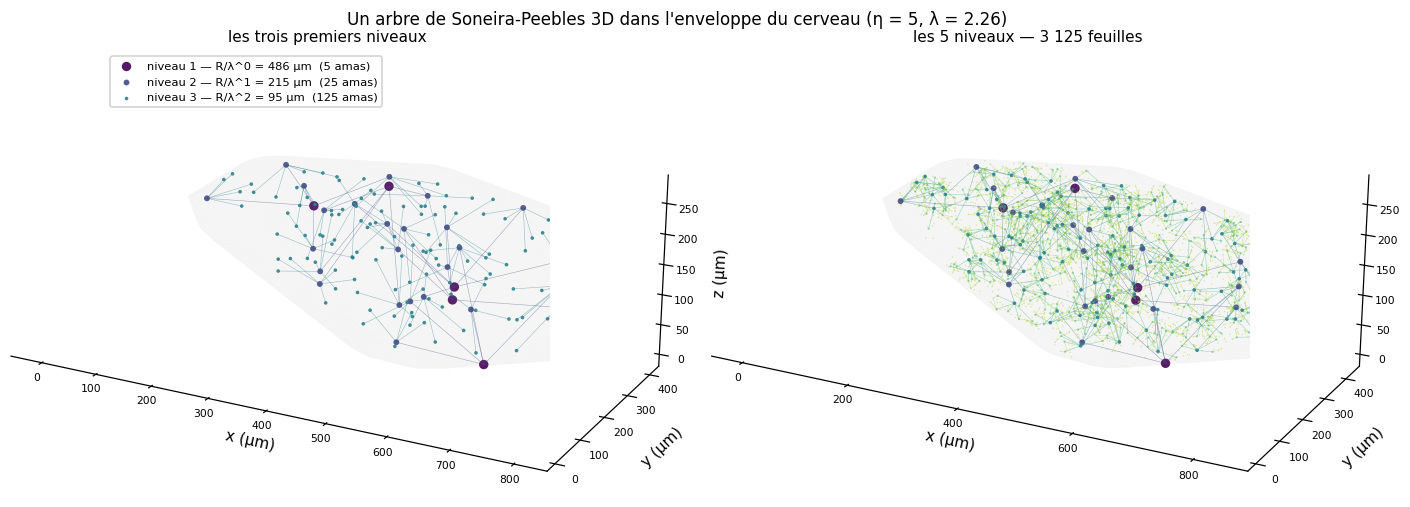

In [4]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

rng_v = np.random.default_rng(SEED + 1)      # flux dédié à l'affichage
eta_v, L_v = 5, 5
lam_v = sph.lambda_of_gamma(eta_v, gamma_d, 3)
_, LV = sph.soneira_peebles_nd(eta_v, lam_v, L_v, R_ref, cen, hull=hull,
                               rng=rng_v, return_levels=True)

def vue_3d(ax, zoom=1.5):
    ax.set_box_aspect(extent, zoom=zoom)
    ax.set_xlabel("x (µm)", labelpad=-6); ax.set_ylabel("y (µm)", labelpad=-6)
    ax.set_zlabel("z (µm)", labelpad=-8)
    ax.tick_params(labelsize=7, pad=-3); ax.grid(False)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.set_alpha(0)
    ax.view_init(elev=20, azim=-62)

V = hull.points / NM
fig = plt.figure(figsize=(13, 4.6))
for k, upto in enumerate([3, L_v]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.add_collection3d(Poly3DCollection([V[s] for s in hull.simplices],
                                         facecolor="0.55", alpha=.04, edgecolor="none"))
    cols = plt.cm.viridis(np.linspace(0, .88, L_v))
    for i in range(upto):
        P = LV[i][0] / NM
        if i > 0:                                     # segments parent -> enfant
            Q = LV[i - 1][0][LV[i][1]] / NM
            seg = np.stack([P, Q], axis=1)
            idx = rng_v.choice(len(seg), min(len(seg), 900), replace=False)
            for a, b in seg[idx]:
                ax.plot(*np.stack([a, b], axis=1), color=cols[i], lw=.35, alpha=.5)
        ax.scatter(*P.T, color=cols[i], s=max(38 / (2.6 ** i), .35),
                   alpha=.9 if i < 3 else .45, lw=0,
                   label=f"niveau {i+1} — R/λ^{i} = {R_ref/lam_v**i/NM:.0f} µm  "
                         f"({len(P):,} amas)".replace(",", " "))
    ax.set_title(("les trois premiers niveaux" if upto == 3 else
                  f"les {L_v} niveaux — {len(LV[-1][0]):,} feuilles").replace(",", " "),
                 fontsize=10)
    vue_3d(ax)
    if upto == 3:
        ax.legend(fontsize=7.5, loc="upper left", framealpha=.9)
fig.suptitle(f"Un arbre de Soneira-Peebles 3D dans l'enveloppe du cerveau "
             f"(η = {eta_v}, λ = {lam_v:.2f})", fontsize=11)
fig.subplots_adjust(left=.01, right=.99, top=.90, bottom=.02, wspace=0)
plt.show()

## 3. La relation λ ↔ γ, vérifiée **sans** domaine

Avant de mesurer quoi que ce soit dans le cerveau, il faut savoir si le
générateur fait ce qu'on croit. La relation λ = η^(1/(3−γ)) est une propriété
de la fractale **infinie et sans bord** : la tester dans l'enveloppe convexe
reviendrait à tester deux choses à la fois. On la teste donc sur l'arbre nu.

**Sans passer par ξ.** La dimension de corrélation se lit directement sur le
nombre de paires à moins de r : N_paires(<r) ∝ r^D. C'est la mesure du § 6 du
notebook 05, ici appliquée au modèle au lieu des données, et elle ne demande
ni domaine, ni catalogue aléatoire, ni ajustement de loi de puissance — donc
aucune des hypothèses qu'on cherche justement à vérifier. La pente est ajustée
entre 3·R/λ^(L−1) (au-dessus du dernier niveau, pour éviter le plateau) et
0.3·R (en dessous du premier, pour éviter la coupure).

In [5]:
def D_pair_count(P, lo, hi, nsub=25000, seed=0, nbins=25):
    """Dimension de corrélation par comptage de paires : pente de N(<r) en
    log-log. Aucun domaine, aucun catalogue aléatoire — cf. § 6 du notebook 05."""
    g = np.random.default_rng(seed)
    P = P[g.choice(len(P), nsub, replace=False)] if len(P) > nsub else P
    re  = np.logspace(np.log10(lo), np.log10(hi), nbins)
    cum = cKDTree(P).count_neighbors(cKDTree(P), re).astype(float) - len(P)
    m   = cum > 0
    return float(np.polyfit(np.log(re[m]), np.log(cum[m]), 1)[0]), re, cum

_c = CACHE / f"free_sp_{SEED}.joblib"
if _c.exists():
    FREE = joblib.load(_c)
else:
    t0, FREE = time.time(), {}
    for eta in l_cluster:
        lam = sph.lambda_of_gamma(eta, gamma_d, 3)
        L   = int(np.ceil(np.log(R_ref / rmin_d) / np.log(lam))) + 1
        while eta ** L > 600_000 and L > 2:      # arbre nu : 6e5 feuilles suffisent
            L -= 1
        P = sph.soneira_peebles_nd(eta, lam, L, R_ref, cen, hull=None,
                                   rng=np.random.default_rng(SEED + eta))
        r_bot = R_ref / lam ** (L - 1)
        D, re, cum = D_pair_count(P, 3 * r_bot, 0.3 * R_ref)
        FREE[eta] = dict(lamb=lam, L=L, n=len(P), r_bot=r_bot, D=D, re=re, cum=cum)
    joblib.dump(FREE, _c)
    print(f"(calcul : {time.time()-t0:.0f} s)")

print(f"dimension visée : D = 3 − γ = {3-gamma_d:.3f}\n")
print(f"{'η':>4}{'λ':>9}{'L':>4}{'feuilles':>11}{'R/λ^(L-1)':>12}{'D mesurée':>12}"
      f"{'écart':>9}")
for eta, v in FREE.items():
    print(f"{eta:>4}{v['lamb']:>9.4f}{v['L']:>4}{v['n']:>11,}{v['r_bot']/NM:>12.2f}"
          f"{v['D']:>12.3f}{v['D']-(3-gamma_d):>9.3f}".replace(",", " "))
print(f"\nmoyenne : {np.mean([v['D'] for v in FREE.values()]):.3f} "
      f"(visée {3-gamma_d:.3f})")

dimension visée : D = 3 − γ = 1.978

   η        λ   L   feuilles   R/λ^(L-1)   D mesurée    écart
   2   1.4198  17    131 072        1.78       1.903   -0.075
   3   1.7429  11    177 147        1.88       1.894   -0.084
   5   2.2566   8    390 625        1.63       1.963   -0.015
   4   2.0158   9    262 144        1.78       1.978    0.000
   6   2.4746   7    279 936        2.11       1.919   -0.059

moyenne : 1.931 (visée 1.978)


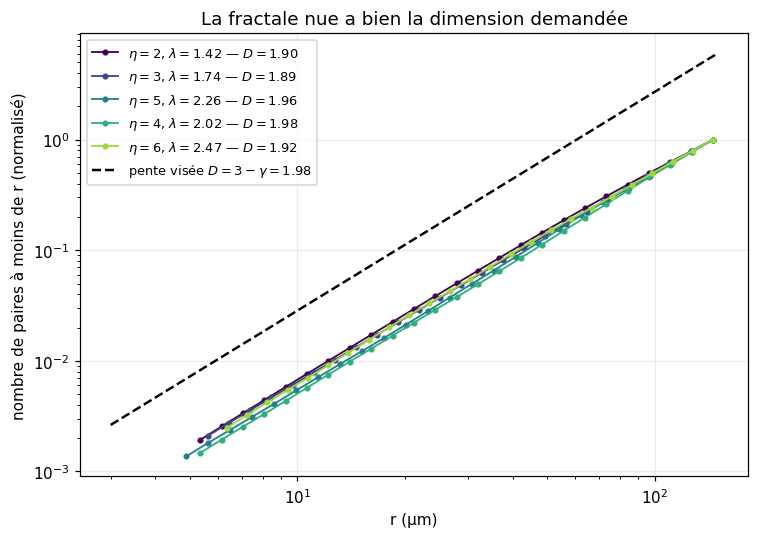

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
cols = plt.cm.viridis(np.linspace(0, .85, len(FREE)))
for (eta, v), col in zip(FREE.items(), cols):
    m = v["cum"] > 0
    ax.plot(v["re"][m]/NM, v["cum"][m]/v["cum"][m][-1], "o-", ms=3, color=col, lw=1.2,
            label=fr"$\eta={eta}$, $\lambda={v['lamb']:.2f}$ — $D={v['D']:.2f}$")
rr = np.logspace(np.log10(3*NM), np.log10(150*NM), 20)
ax.plot(rr/NM, 3e-4*(rr/NM)**(3-gamma_d), "k--", lw=1.6,
        label=fr"pente visée $D=3-\gamma={3-gamma_d:.2f}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (µm)"); ax.set_ylabel("nombre de paires à moins de r (normalisé)")
ax.set_title("La fractale nue a bien la dimension demandée")
ax.legend(fontsize=8.5)
fig.tight_layout(); plt.show()

## 4. L'estimateur, à l'identique — et la loi radiale

L'estimateur est celui du notebook 05 (Landy-Szalay, schéma des catalogues
scindés de Keihanen et al. 2019) : `compute_LS_correlation_2019` est appelée
telle quelle, sur des comptages de paires par double KD-tree. Deux choix
méritent d'être explicités, parce qu'ils décident de ce que la comparaison
modèle ↔ données veut dire.

**Les catalogues aléatoires sont partagés.** Ils ne dépendent que du domaine,
identique des deux côtés : les mêmes servent aux données et à tous les modèles.
Cela divise le temps de calcul par deux et, surtout, supprime une source de
variance — modèle et données sont normalisés par le même RR. C'est aussi la
réponse pratique à la limite principale du notebook 05 (§ 8) : *comparer avec le
même domaine imparfait des deux côtés*, pour que le biais d'enveloppe convexe
s'annule au lieu de se propager.

**La fenêtre d'ajustement est imposée.** Les données sont ajustées entre 2.2 et
135 µm (notebook 05, § 5). Le modèle, lui, garde une ξ positive plus loin :
l'ajuster sur *ses* bins mesurables donnerait une pente qui ne se compare à
rien. On lui impose donc la fenêtre des données — et on vérifie que sur ces
bins-là, le fit redonne bien γ = 1.022 sur les données elles-mêmes.

In [7]:
# Catalogues aléatoires partagés — ils ne dépendent que du domaine.
rng  = np.random.default_rng(SEED)
CATS = [mtpc.sample_in_hull(hull, Nr_prime, rng) for _ in range(N_run)]
RR   = sum(mtpc.pair_counts(c, r_edges) for c in CATS)

def xi_nd(pts, k=3, rng=rng):
    """2PCF de Landy-Szalay (Keihanen 2019), l'estimateur du notebook 05 à ceci
    près que les catalogues aléatoires sont ceux calculés ci-dessus."""
    out = []
    for _ in range(k):
        sub = pts if len(pts) <= Nsample else \
              pts[rng.choice(len(pts), Nsample, replace=False)]
        DD  = mtpc.pair_counts(sub, r_edges)
        DR  = sum(mtpc.pair_counts(sub, r_edges, B=c) for c in CATS)
        out.append(mtpc.compute_LS_correlation_2019(DD, DR, RR, len(sub),
                                                    Nr_prime, Nr_prime * N_run))
    return np.array(out)

def power_law(r, gamma, r0):
    return (r / r0) ** (-gamma)

FIT_HI = 135.0 * NM
WIN    = (r_c >= r_c[0] * 0.999) & (r_c <= FIT_HI * 1.001)

def fit_pl(xi, err, dim=3):
    """Ajustement en loi de puissance, borné par la dimension (cf. notebook 05,
    § 5 : ne pas réutiliser sp_helpers.fit_2pcf, borné à 1.95 pour le plan)."""
    m = WIN & (xi > 0)
    popt, pcov = curve_fit(power_law, r_c[m], xi[m],
                           sigma=np.maximum(err[m], 0.02 * xi[m]),
                           p0=[1.0, r_c[m][0]], bounds=([1e-3, 1.0], [dim, 1e9]),
                           maxfev=20000)
    perr = np.sqrt(np.diag(pcov))
    return dict(gamma=popt[0], r0=popt[1], gamma_err=perr[0], r0_err=perr[1],
                nbins=int(m.sum()))

f_data = fit_pl(xi_data, err_data)
print(f"contrôle — le fit refait ici sur les données redonne "
      f"γ = {f_data['gamma']:.3f} ± {f_data['gamma_err']:.3f}, "
      f"r0 = {f_data['r0']/NM:.1f} µm sur {f_data['nbins']} bins "
      f"({r_c[WIN][0]/NM:.1f} → {r_c[WIN][-1]/NM:.0f} µm)")

contrôle — le fit refait ici sur les données redonne γ = 1.022 ± 0.036, r0 = 19.5 µm sur 17 bins (2.2 → 135 µm)


### La loi radiale : le détail qui ne se voit pas

Le code 2D tire l'enfant à `r = R·u` avec u uniforme sur [0, 1]. Ce n'est
uniforme **dans aucune dimension supérieure à 1** : la densité d'un tel tirage
varie en r^(1−d), donc en 1/r² dans la boule. Soneira & Peebles placent leurs
sous-amas **uniformément dans la sphère**, ce qui demande r = R·u^(1/3).

Ce détail ne change pas la dimension fractale — celle-ci est fixée par le
comptage des amas, η par niveau, pas par la façon de les répartir à
l'intérieur. Il change en revanche la structure **à l'intérieur** de chaque
amas, donc l'amplitude de ξ aux petits r. `sample_in_ball(..., radial=...)`
implémente les deux, et la cellule suivante mesure l'écart plutôt que de le
supposer.

In [8]:
_c = CACHE / f"radial_{SEED}.joblib"
if _c.exists():
    RAD = joblib.load(_c)
else:
    t0, RAD = time.time(), {}
    eta_r = 5
    lam_r = sph.lambda_of_gamma(eta_r, gamma_d, 3)
    L_r   = int(np.ceil(np.log(R_ref / rmin_d) / np.log(lam_r))) + 1
    for law in ("uniform", "linear"):
        g = np.random.default_rng(SEED + 7)          # même graine pour les deux
        libre = sph.soneira_peebles_nd(eta_r, lam_r, L_r, R_ref, cen, hull=None,
                                       rng=g, radial=law)
        g = np.random.default_rng(SEED + 7)
        dans = sph.soneira_peebles_nd(eta_r, lam_r, L_r, R_ref, cen, hull=hull,
                                      rng=g, radial=law)
        l = xi_nd(dans, k=3, rng=g); xi_r = l.mean(axis=0)
        RAD[law] = dict(D=D_pair_count(libre, 3 * R_ref / lam_r ** (L_r - 1),
                                       0.3 * R_ref)[0],
                        xi=xi_r, fit=fit_pl(xi_r, l.std(axis=0)),
                        eta=eta_r, lamb=lam_r, L=L_r, n=len(dans))
    joblib.dump(RAD, _c)
    print(f"(calcul : {time.time()-t0:.0f} s)")

print(f"η = {RAD['uniform']['eta']}, λ = {RAD['uniform']['lamb']:.3f}, "
      f"L = {RAD['uniform']['L']} — seule la loi radiale change\n")
print(f"{'loi radiale':<32}{'D (arbre nu)':>14}{'γ (dans le domaine)':>22}"
      f"{'ξ(2.2 µm)':>12}{'ξ(17 µm)':>11}")
for law, txt in [("uniform", "r = R·u^(1/3)  (Soneira-Peebles)"),
                 ("linear",  "r = R·u        (code 2D)")]:
    v = RAD[law]
    print(f"{txt:<32}{v['D']:>14.3f}{v['fit']['gamma']:>22.3f}"
          f"{v['xi'][0]:>12.2f}{v['xi'][8]:>11.2f}")
print(f"{'données':<32}{'—':>14}{gamma_d:>22.3f}{xi_data[0]:>12.2f}{xi_data[8]:>11.2f}")

η = 5, λ = 2.257, L = 8 — seule la loi radiale change

loi radiale                       D (arbre nu)   γ (dans le domaine)   ξ(2.2 µm)   ξ(17 µm)
r = R·u^(1/3)  (Soneira-Peebles)         1.978                 0.919       12.55       1.90
r = R·u        (code 2D)                 1.974                 0.921       27.27       4.56
données                                      —                 1.022       11.05       1.06


## 5. La profondeur L, et pourquoi elle ne doit pas dépendre de N

Le code 2D pose `L = int(log(N)/log(eta))` : la profondeur de l'arbre est
choisie pour que η^L tombe près du nombre de points des données. C'est un
couplage inutile, et nuisible — il fait dépendre la **portée** de la loi de
puissance (λ^(L−1), § 2) d'une quantité qui n'a rien à y voir, la taille du
catalogue.

Or ξ(r) est **invariante par sous-échantillonnage aléatoire** : c'est un
rapport de densités de paires, et retirer des points au hasard divise les
comptages de données et d'aléatoires par le même facteur. (C'est déjà
l'argument qui autorise `Nsample = 20 000` au notebook 05, et c'est ce que fait
`erase_nodes` chez Presigny.) On peut donc choisir L pour la portée, puis
ramener le nuage à N points en tirant au sort.

Deux contraintes, dans cet ordre :

1. **descendre sous le premier bin** : R/λ^(L−1) ≤ rmin = 2.0 µm, sinon les
   premiers points de ξ tombent dans la zone plate ;
2. **fournir assez de feuilles** : η^L ≥ N, sinon il n'y a rien à
   sous-échantillonner ;

et un plafond de 2·10⁶ feuilles, pour que η = 6 — dont l'arbre grossit le plus
vite — reste calculable.

In [9]:
def depth(eta, lamb, n_target, n_max=2_000_000):
    """L : (1) R/λ^(L-1) sous rmin, (2) au moins n_target feuilles, (3) plafond."""
    L_bot = int(np.ceil(np.log(R_ref / rmin_d) / np.log(lamb))) + 1   # portée
    L_num = int(np.ceil(np.log(n_target) / np.log(eta)))              # effectif
    L = max(L_bot, L_num)
    while eta ** L > n_max and L > 2:
        L -= 1
    return L, L_bot, L_num

print(f"{'η':>4}{'λ':>9}{'L (portée)':>12}{'L (effectif)':>14}{'L retenu':>10}"
      f"{'feuilles':>12}{'R/λ^(L-1)':>12}{'portée λ^(L-1)':>16}")
for eta in l_cluster:
    lam = sph.lambda_of_gamma(eta, gamma_d, 3)
    L, L_bot, L_num = depth(eta, lam, N)
    print(f"{eta:>4}{lam:>9.4f}{L_bot:>12}{L_num:>14}{L:>10}{eta**L:>12,}"
          f"{R_ref/lam**(L-1)/NM:>12.2f}{lam**(L-1):>16.0f}".replace(",", " "))
print(f"\nrmin des données = {rmin_d/NM:.2f} µm ; la loi de puissance mesurée "
      f"couvre {r_c[WIN][0]/NM:.1f} → {r_c[WIN][-1]/NM:.0f} µm, "
      f"soit un facteur {r_c[WIN][-1]/r_c[WIN][0]:.0f}.")

   η        λ  L (portée)  L (effectif)  L retenu    feuilles   R/λ^(L-1)  portée λ^(L-1)
   2   1.4198          17            18        18     262 144        1.25             387
   3   1.7429          11            12        12     531 441        1.08             451
   5   2.2566           8             8         8     390 625        1.63             298
   4   2.0158           9             9         9     262 144        1.78             273
   6   2.4746           8             7         8   1 679 616        0.85             568

rmin des données = 1.96 µm ; la loi de puissance mesurée couvre 2.2 → 135 µm, soit un facteur 60.


## 6. Le fond aléatoire, et le balayage sur η

### Pourquoi un fond aléatoire

Une fractale pure a la bonne **pente** par construction, mais son **amplitude**
n'est pas libre : elle est fixée par η, λ et le domaine. Le modèle du repo la
règle en diluant le fractal dans un fond de points uniformes — le « SP mixte »
des notebooks 01-04 et 06.

L'arithmétique est simple et exacte. Si le nuage contient n_SP points fractals
et n_rand points indépendants uniformes, seules les paires fractal-fractal sont
corrélées, et elles représentent une fraction f² = (n_SP/N)² de toutes les
paires :

$$\xi_{\rm mix}(r) = f^2\,\xi_{\rm SP}(r), \qquad f = \frac{n_{\rm SP}}{N}$$

d'où la recette : mesurer ρ = ⟨ξ_data/ξ_SP⟩ sur la fenêtre ajustée, poser
**f = √ρ**, et compléter à N avec du fond. C'est exactement le
`n_rand = m_SP·(1/√ρ − 1)` de `sp_helpers`, écrit autrement.

⚠️ Ici ρ sera **proche de 1**. Avec R = rayon circonscrit, le domaine a déjà
raboté le haut de la hiérarchie (§ 2) et la fractale contrainte est nettement
moins contrastée que sa version libre : le fond aléatoire ne fera qu'une
correction de quelques pour cent, là où il pèse ~25 % dans le cas 2D des postes
électriques (notebook 06). **Ce n'est pas un réglage libre de plus, c'est une
mesure** — et elle dit que sur ce système, le fractal seul est presque
suffisant.

### Le balayage

Pour chacun des cinq η candidats : λ = η^(1/(3−γ)), L par `depth`, l'arbre, sa
ξ, la calibration ρ → f, le mélange, sa ξ, et un coût. **Trois arbres
indépendants par η** — la § 7 dira pourquoi ce n'est pas un luxe.

Le coût est l'écart quadratique moyen en **log** entre ξ_mix et ξ_data sur la
fenêtre ajustée : ξ variant d'un facteur 140 sur cette plage, un écart
euclidien brut (celui de `fit_Soneira_Peebles`) ne verrait que les deux ou
trois premiers bins. Les deux sont calculés.

In [10]:
def build_sp(eta, rng, n_target=N):
    """Arbre complet dans le domaine, aux paramètres du modèle."""
    lam = sph.lambda_of_gamma(eta, gamma_d, 3)
    L, _, _ = depth(eta, lam, n_target)
    return sph.soneira_peebles_nd(eta, lam, L, R_ref, cen, hull=hull, rng=rng), lam, L

def calibrate(xi_sp):
    """ρ = <ξ_data/ξ_SP> sur la fenêtre ajustée → fraction fractale f = √ρ."""
    sel = WIN & (xi_sp > 0) & (xi_data > 0)
    rho = float(np.mean(xi_data[sel] / xi_sp[sel]))
    return rho, float(min(np.sqrt(rho), 1.0))

def build_mixture(S, frac, rng, n_target=N):
    """n_SP points du fractal (tirés au sort) + le complément uniforme."""
    n_sp = min(int(round(frac * n_target)), len(S))
    n_rd = n_target - n_sp
    M    = S[rng.choice(len(S), n_sp, replace=False)]
    if n_rd > 0:
        M = np.vstack([M, mtpc.sample_in_hull(hull, n_rd, rng)])
    return M, n_sp, n_rd

N_TRY = 3                       # arbres indépendants par η
_c = CACHE / f"scan3_{SEED}.joblib"
if _c.exists():
    SCAN = joblib.load(_c)
    print("balayage : chargé du cache")
else:
    t0, SCAN = time.time(), {}
    for eta in l_cluster:
        for t in range(N_TRY):
            g = np.random.default_rng(SEED + 1000 * t + eta)
            S, lam, L = build_sp(eta, g)
            l_sp = xi_nd(S, k=3, rng=g); xi_sp = l_sp.mean(axis=0)
            f_sp = fit_pl(xi_sp, l_sp.std(axis=0))
            rho, frac = calibrate(xi_sp)
            M, n_sp, n_rd = build_mixture(S, frac, g)
            l_mx = xi_nd(M, k=3, rng=g); xi_mx = l_mx.mean(axis=0)
            f_mx = fit_pl(xi_mx, l_mx.std(axis=0))
            s2   = WIN & (xi_mx > 0) & (xi_data > 0)
            SCAN[(eta, t)] = dict(
                lamb=lam, L=L, n_leaves=len(S), r_bot=R_ref / lam ** (L - 1),
                xi_sp=xi_sp, xi_sp_std=l_sp.std(axis=0), gamma_sp=f_sp["gamma"],
                gamma_sp_err=f_sp["gamma_err"], r0_sp=f_sp["r0"],
                rho=rho, frac=frac, N_sp=n_sp, N_rd=n_rd,
                xi_mx=xi_mx, xi_mx_std=l_mx.std(axis=0), gamma_mx=f_mx["gamma"],
                gamma_mx_err=f_mx["gamma_err"], r0_mx=f_mx["r0"],
                cost=float(np.sqrt(np.mean(np.log10(xi_mx[s2] / xi_data[s2]) ** 2))),
                cost_eucl=float(np.linalg.norm(xi_mx[WIN] - xi_data[WIN])))
    joblib.dump(SCAN, _c)
    print(f"(balayage : {len(l_cluster)*N_TRY} modèles en {time.time()-t0:.0f} s)")

def agg(eta, key):
    v = [SCAN[(eta, t)][key] for t in range(N_TRY)]
    return float(np.mean(v)), float(np.std(v))

print(f"\n{'η':>3}{'λ':>7}{'L':>4}{'feuilles':>10}{'γ_SP':>15}{'ρ':>15}"
      f"{'f':>7}{'n_rand':>9}{'γ_mix':>15}{'r0_mix':>9}{'coût':>15}")
for eta in l_cluster:
    v = SCAN[(eta, 0)]
    g_sp, g_mx, rh, fr, r0m, co = (agg(eta, k) for k in
                                   ("gamma_sp", "gamma_mx", "rho", "frac", "r0_mx", "cost"))
    print(f"{eta:>3}{v['lamb']:>7.3f}{v['L']:>4}{v['n_leaves']:>10,}"
          f"{g_sp[0]:>9.3f}±{g_sp[1]:.3f}{rh[0]:>9.3f}±{rh[1]:.3f}{fr[0]:>7.3f}"
          f"{int(round((1-fr[0])*N)):>9,}{g_mx[0]:>9.3f}±{g_mx[1]:.3f}"
          f"{r0m[0]/NM:>9.1f}{co[0]:>9.4f}±{co[1]:.4f}".replace(",", " "))
print(f"\n{'données':>3}{'':>7}{'':>4}{'':>10}{gamma_d:>9.3f}±{f_data['gamma_err']:.3f}"
      f"{'':>16}{'':>7}{'':>9}{'':>16}{r0_d/NM:>9.1f}")

balayage : chargé du cache

  η      λ   L  feuilles           γ_SP              ρ      f   n_rand          γ_mix   r0_mix           coût
  2  1.420  18   262 144    1.146±0.253    0.925±0.328  0.890   26 276    1.116±0.265     19.3   0.1674±0.0791
  3  1.743  12   531 441    1.043±0.081    0.674±0.050  0.821   42 855    1.004±0.046     19.9   0.0636±0.0128
  5  2.257   8   390 625    1.170±0.132    0.922±0.163  0.945   13 254    1.122±0.102     20.2   0.1167±0.0309
  4  2.016   9   262 144    1.179±0.089    0.939±0.118  0.952   11 431    1.207±0.133     19.0   0.1401±0.0485
  6  2.475   8 1 679 616    0.999±0.051    0.753±0.059  0.867   31 707    1.045±0.118     19.4   0.2080±0.1850

données                         1.022±0.036                                                     19.5


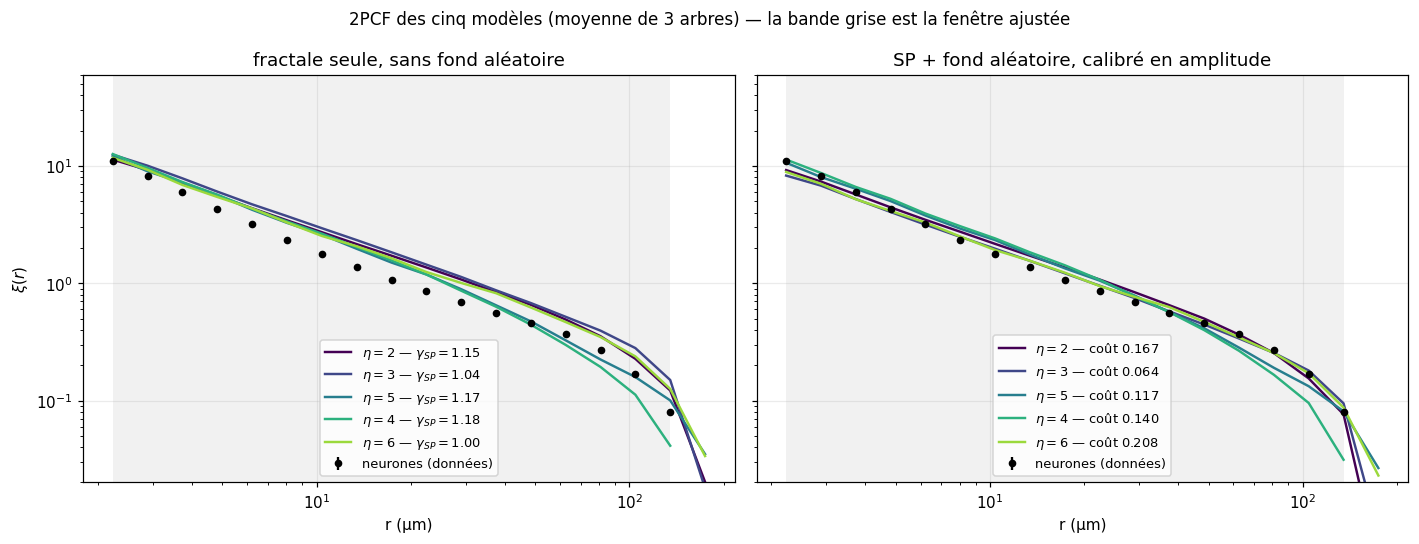

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
cols = plt.cm.viridis(np.linspace(0, .85, len(l_cluster)))

ax = axes[0]
for eta, col in zip(l_cluster, cols):
    xi_s = np.mean([SCAN[(eta, t)]["xi_sp"] for t in range(N_TRY)], axis=0)
    p = xi_s > 0
    ax.plot(r_c[p]/NM, xi_s[p], "-", color=col, lw=1.6,
            label=fr"$\eta={eta}$ — $\gamma_{{SP}}={agg(eta,'gamma_sp')[0]:.2f}$")
ax.errorbar(r_c/NM, np.where(xi_data > 0, xi_data, np.nan), yerr=err_data, fmt="o",
            ms=4, color=C["data"], label="neurones (données)", zorder=5)
ax.set_title("fractale seule, sans fond aléatoire")

ax = axes[1]
for eta, col in zip(l_cluster, cols):
    xi_m = np.mean([SCAN[(eta, t)]["xi_mx"] for t in range(N_TRY)], axis=0)
    p = xi_m > 0
    ax.plot(r_c[p]/NM, xi_m[p], "-", color=col, lw=1.6,
            label=fr"$\eta={eta}$ — coût {agg(eta,'cost')[0]:.3f}")
ax.errorbar(r_c/NM, np.where(xi_data > 0, xi_data, np.nan), yerr=err_data, fmt="o",
            ms=4, color=C["data"], label="neurones (données)", zorder=5)
ax.set_title("SP + fond aléatoire, calibré en amplitude")

for ax in axes:
    ax.axvspan(r_c[WIN][0]/NM, r_c[WIN][-1]/NM, color="0.85", alpha=.35, lw=0, zorder=0)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(2e-2, 6e1)
    ax.set_xlabel("r (µm)"); ax.legend(fontsize=8.5)
axes[0].set_ylabel(r"$\xi(r)$")
fig.suptitle("2PCF des cinq modèles (moyenne de 3 arbres) — la bande grise est la "
             "fenêtre ajustée", fontsize=11)
fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_2pcf_scan.pdf", bbox_inches="tight")
plt.show()

## 7. η est-il identifiable ? Non — et c'est structurel

Le tableau du § 6 est décevant si on le lit comme un classement, et instructif
si on le lit comme une mesure. Deux choses s'y voient.

**Ce que ξ ne peut pas voir.** La 2PCF d'une fractale de Soneira-Peebles ne
dépend de η et λ **qu'à travers D = ln η / ln λ** — et c'est précisément la
quantité qu'on a fixée en posant λ = η^(1/(3−γ)). Les cinq modèles ont donc, par
construction, la même dimension et la même pente attendue ; ils ne diffèrent que
par leur *lacunarité*, la façon dont les vides se répartissent à dimension
égale. **Aucune 2PCF ne peut trancher entre eux**, et le fait que les cinq coûts
tiennent dans un mouchoir n'est pas un échec de la calibration : c'est la
réponse. C'est le score de silhouette (notebook 05, § 9) qui propose η, et rien
dans ξ ne le confirme ni ne l'infirme.

**Ce que η change quand même : la variance.** Les premiers niveaux de l'arbre ne
contiennent que quelques amas — η au niveau 1, η² au niveau 2 — et ce sont eux
qui portent toute la structure aux grandes échelles. Un tirage malheureux à ce
stade ne se corrige pas plus bas. C'est de la variance d'échantillonnage au sens
strict : l'équivalent, à l'échelle d'un cerveau, de la *cosmic variance* des
cosmologistes, qui n'ont qu'un seul univers pour estimer une moyenne d'ensemble.

À η = 2 l'effet est direct — le niveau 1 tient en **deux** points, et d'un arbre
à l'autre la pente ajustée va de 0.82 à 1.46 et ρ de 0.60 à 1.38, les plus
grands intervalles du balayage. Aux grands η, ce n'est pas la pente qui bouge
mais le **grand r** : à η = 6, λ = 2.47 et L = 8, un seul des trois arbres suffit
à faire chuter ξ au-delà de 100 µm et le coût passe de 0.065 à 0.469. Les deux
bouts du balayage sont donc instables, pour deux raisons différentes, et c'est le
milieu — η = 3 — qui est à la fois le plus bas et le plus serré (0.064 ± 0.013).

**Conséquence pratique.** On ne choisit pas η pour ajuster ξ (impossible), mais
pour que le modèle soit **reproductible**. La figure ci-dessous montre les trois
arbres de η = 2 et ceux du plus grand candidat, à paramètres identiques.

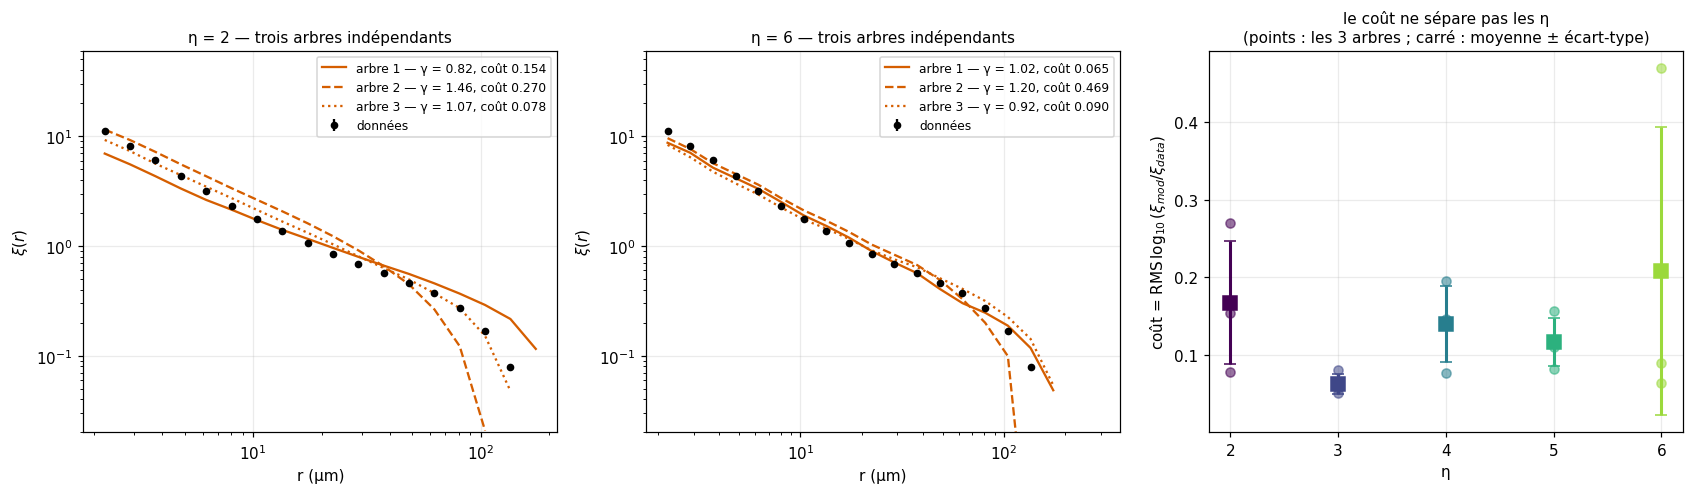

   η   coût moyen   écart-type    ρ min    ρ max   γ_mix min   γ_mix max
   2       0.1674       0.0791     0.60     1.38       0.817       1.460
   3       0.0636       0.0128     0.61     0.72       0.951       1.063
   4       0.1401       0.0485     0.80     1.09       1.060       1.382
   5       0.1167       0.0309     0.69     1.07       0.984       1.229
   6       0.2080       0.1850     0.68     0.83       0.916       1.201

écart entre le meilleur et le pire η : 0.1444   |   dispersion typique d'un arbre à l'autre : 0.0712


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))
for ax, eta in zip(axes[:2], [l_cluster[0], max(l_cluster)]):
    for t, ls in zip(range(N_TRY), ["-", "--", ":"]):
        xi_m = SCAN[(eta, t)]["xi_mx"]; p = xi_m > 0
        ax.plot(r_c[p]/NM, xi_m[p], ls, color=C["sp"], lw=1.5,
                label=f"arbre {t+1} — γ = {SCAN[(eta,t)]['gamma_mx']:.2f}, "
                      f"coût {SCAN[(eta,t)]['cost']:.3f}")
    ax.errorbar(r_c/NM, np.where(xi_data > 0, xi_data, np.nan), yerr=err_data,
                fmt="o", ms=4, color=C["data"], label="données", zorder=5)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(2e-2, 6e1)
    ax.set_xlabel("r (µm)"); ax.set_ylabel(r"$\xi(r)$")
    ax.set_title(f"η = {eta} — trois arbres indépendants", fontsize=10)
    ax.legend(fontsize=8)

ax = axes[2]
for eta, col in zip(sorted(l_cluster), plt.cm.viridis(np.linspace(0, .85, len(l_cluster)))):
    cs = [SCAN[(eta, t)]["cost"] for t in range(N_TRY)]
    ax.plot([eta]*N_TRY, cs, "o", color=col, ms=6, alpha=.55)
    ax.errorbar([eta], [np.mean(cs)], yerr=[np.std(cs)], fmt="s", color=col, ms=9,
                capsize=4, lw=2)
ax.set_xlabel("η"); ax.set_ylabel(r"coût = RMS$\,\log_{10}(\xi_{mod}/\xi_{data})$")
ax.set_title("le coût ne sépare pas les η\n(points : les 3 arbres ; "
             "carré : moyenne ± écart-type)", fontsize=10)
ax.set_xticks(sorted(l_cluster))
fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_variance.pdf", bbox_inches="tight")
plt.show()

print(f"{'η':>4}{'coût moyen':>13}{'écart-type':>13}{'ρ min':>9}{'ρ max':>9}"
      f"{'γ_mix min':>12}{'γ_mix max':>12}")
for eta in sorted(l_cluster):
    cs  = [SCAN[(eta, t)]["cost"] for t in range(N_TRY)]
    rhs = [SCAN[(eta, t)]["rho"] for t in range(N_TRY)]
    gms = [SCAN[(eta, t)]["gamma_mx"] for t in range(N_TRY)]
    print(f"{eta:>4}{np.mean(cs):>13.4f}{np.std(cs):>13.4f}{min(rhs):>9.2f}"
          f"{max(rhs):>9.2f}{min(gms):>12.3f}{max(gms):>12.3f}")
ec = [agg(e, "cost")[0] for e in l_cluster]
print(f"\nécart entre le meilleur et le pire η : {max(ec)-min(ec):.4f}"
      f"   |   dispersion typique d'un arbre à l'autre : "
      f"{np.mean([agg(e,'cost')[1] for e in l_cluster]):.4f}")

## 8. Le modèle retenu

On garde le η de coût moyen minimal, on regénère un arbre avec sa propre graine
et on mesure sa 2PCF avec **exactement** les paramètres des données du
notebook 05 (`k = 8` réalisations, `N_run = 4` catalogues de 20 000 points,
`Nsample = 20 000`) — même estimateur, même domaine, mêmes bins, même nombre de
points. La comparaison ne repose alors sur aucune correction.

In [13]:
eta_star  = min(l_cluster, key=lambda e: agg(e, "cost")[0])
frac_star = agg(eta_star, "frac")[0]

_c = CACHE / f"final_{SEED}_{eta_star}.joblib"
if _c.exists():
    FIN = joblib.load(_c)
else:
    t0 = time.time()
    g = np.random.default_rng(SEED + 999)
    S_f, lam_f, L_f = build_sp(eta_star, g)
    l_sp = xi_nd(S_f, k=4, rng=g)
    rho_f, frac_f = calibrate(l_sp.mean(axis=0))
    M_f, n_sp_f, n_rd_f = build_mixture(S_f, frac_f, g)
    l_mx = xi_nd(M_f, k=8, rng=g)                    # k = 8, comme les données
    FIN = dict(eta=eta_star, lamb=lam_f, L=L_f, n_leaves=len(S_f),
               xi_sp=l_sp.mean(axis=0), xi_sp_std=l_sp.std(axis=0),
               rho=rho_f, frac=frac_f, N_sp=n_sp_f, N_rd=n_rd_f,
               l_xi=l_mx, xi=l_mx.mean(axis=0), xi_std=l_mx.std(axis=0),
               model=M_f)
    joblib.dump(FIN, _c)
    print(f"(modèle final : {time.time()-t0:.0f} s)")

fit_mx = fit_pl(FIN["xi"], FIN["xi_std"])
fit_sp = fit_pl(FIN["xi_sp"], FIN["xi_sp_std"])
MODEL  = FIN["model"]
print(f"η = {FIN['eta']}   λ = {FIN['lamb']:.4f}   L = {FIN['L']}   "
      f"feuilles = {FIN['n_leaves']:,}".replace(",", " "))
print(f"  perdues au rejet (hors enveloppe) : "
      f"{100*(1 - FIN['n_leaves']/FIN['eta']**FIN['L']):.1f} % des η^L")
print(f"  ρ = {FIN['rho']:.3f} → f = {FIN['frac']:.3f} : {FIN['N_sp']:,} points "
      f"fractals + {FIN['N_rd']:,} de fond = {len(MODEL):,}".replace(",", " "))
print(f"\n{'':<22}{'γ':>18}{'r0 (µm)':>16}{'ξ(2.2 µm)':>12}{'ξ(17 µm)':>11}")
print(f"{'données':<22}{gamma_d:>11.3f} ± {f_data['gamma_err']:.3f}"
      f"{r0_d/NM:>10.1f} ± {f_data['r0_err']/NM:.1f}{xi_data[0]:>12.2f}{xi_data[8]:>11.2f}")
print(f"{'SP + fond (modèle)':<22}{fit_mx['gamma']:>11.3f} ± {fit_mx['gamma_err']:.3f}"
      f"{fit_mx['r0']/NM:>10.1f} ± {fit_mx['r0_err']/NM:.1f}"
      f"{FIN['xi'][0]:>12.2f}{FIN['xi'][8]:>11.2f}")
print(f"{'fractale seule':<22}{fit_sp['gamma']:>11.3f} ± {fit_sp['gamma_err']:.3f}"
      f"{fit_sp['r0']/NM:>10.1f} ± {fit_sp['r0_err']/NM:.1f}"
      f"{FIN['xi_sp'][0]:>12.2f}{FIN['xi_sp'][8]:>11.2f}")
sel = WIN & (FIN["xi"] > 0) & (xi_data > 0)
print(f"\nécart |ξ_mod/ξ_data − 1| sur la fenêtre : médiane "
      f"{100*np.median(np.abs(FIN['xi'][sel]/xi_data[sel] - 1)):.0f} %, "
      f"max {100*np.max(np.abs(FIN['xi'][sel]/xi_data[sel] - 1)):.0f} %")

η = 3   λ = 1.7429   L = 12   feuilles = 531 441
  perdues au rejet (hors enveloppe) : 0.0 % des η^L
  ρ = 0.658 → f = 0.811 : 193 783 points fractals + 45 126 de fond = 238 909

                                       γ         r0 (µm)   ξ(2.2 µm)   ξ(17 µm)
données                     1.022 ± 0.036      19.5 ± 0.7       11.05       1.06
SP + fond (modèle)          0.955 ± 0.009      20.2 ± 0.2        8.05       1.17
fractale seule              0.949 ± 0.008      31.5 ± 0.4       12.04       1.76

écart |ξ_mod/ξ_data − 1| sur la fenêtre : médiane 8 %, max 80 %


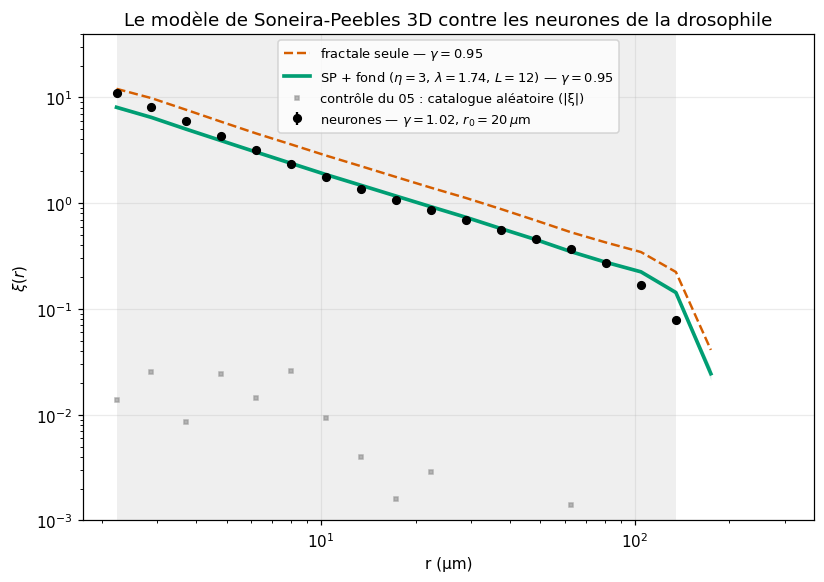

In [14]:
fig, ax = plt.subplots(figsize=(7.6, 5.4))
ax.axvspan(r_c[WIN][0]/NM, r_c[WIN][-1]/NM, color="0.88", alpha=.5, lw=0, zorder=0)
ax.errorbar(r_c/NM, np.where(xi_data > 0, xi_data, np.nan), yerr=err_data, fmt="o",
            ms=5, color=C["data"], zorder=6,
            label=fr"neurones — $\gamma={gamma_d:.2f}$, $r_0={r0_d/NM:.0f}\,\mu$m")
p = FIN["xi_sp"] > 0
ax.plot(r_c[p]/NM, FIN["xi_sp"][p], "--", color=C["sp"], lw=1.6,
        label=fr"fractale seule — $\gamma={fit_sp['gamma']:.2f}$")
p = FIN["xi"] > 0
ax.plot(r_c[p]/NM, FIN["xi"][p], "-", color=C["mix"], lw=2.4, zorder=5,
        label=fr"SP + fond ($\eta={FIN['eta']}$, $\lambda={FIN['lamb']:.2f}$, "
              fr"$L={FIN['L']}$) — $\gamma={fit_mx['gamma']:.2f}$")
ax.fill_between(r_c[p]/NM, np.clip(FIN["xi"] - FIN["xi_std"], 1e-3, None)[p],
                (FIN["xi"] + FIN["xi_std"])[p], color=C["mix"], alpha=.18, lw=0)
ax.plot(r_c/NM, np.abs(d["xi_random"]), "s", ms=3, color=C["random"], alpha=.7,
        label="contrôle du 05 : catalogue aléatoire (|ξ|)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-3, 4e1)
ax.set_xlabel("r (µm)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("Le modèle de Soneira-Peebles 3D contre les neurones de la drosophile")
ax.legend(fontsize=8.5)
fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_2pcf.pdf", bbox_inches="tight")
plt.show()

## 9. Deuxième métrique : divergence de Kullback-Leibler des distances

La 2PCF a servi à **construire** le modèle : elle ne peut pas ensuite servir à le
juger, sauf à noter une copie sur son propre corrigé. Il faut une mesure que la
calibration n'a pas vue. Presigny en utilise une dans la partie III : la
**divergence de Kullback-Leibler entre les distributions de distances par
paires**.

D_KL(P‖Q) = Σ P(r) ln(P(r)/Q(r)) mesure l'information perdue quand on remplace
la vraie distribution P par le modèle Q ; elle vaut 0 si et seulement si
P = Q, et n'est pas symétrique. Ici P est la distribution des distances entre
neurones (histogramme sur les mêmes `r_edges`, stocké par le notebook 05 sur
50 000 points), Q celle du modèle.

Deux remarques la rendent lisible :

- **La comparaison est légitime à tailles d'échantillon différentes** (50 000 pour
  les données, 30 000 ici) : la *forme* normalisée de la distribution des
  distances est, comme ξ, invariante par éclaircissement aléatoire.
- **Une divergence ne se lit que relativement.** On la compare donc à celle du
  catalogue **uniforme** dans la même enveloppe — le modèle nul du notebook 05.
  Si le SP n'améliore pas l'uniforme, il n'apporte rien ; le rapport des deux
  divergences est le gain réel du modèle.

In [15]:
N_KL, N_UNI, n_kl = 8, 8, 30_000

def pdist_hist(P, rng, n=n_kl):
    """Distribution normalisée des distances par paires, sur les bins des données."""
    sub = P if len(P) <= n else P[rng.choice(len(P), n, replace=False)]
    h = mtpc.pair_counts(sub, r_edges).astype(float)
    return h / h.sum()

def kl_div(p, q, eps=1e-12):
    q = np.clip(q, eps, None); m = p > 0
    return float(np.sum(p[m] * np.log(p[m] / q[m])))

P_data = d["distance_distribution"] / d["distance_distribution"].sum()

_c = CACHE / f"kl_{SEED}_{eta_star}.joblib"
if _c.exists():
    KL = joblib.load(_c)
else:
    t0 = time.time()
    kl_mod, kl_uni, H_mod, H_uni = [], [], [], []
    for i in range(N_KL):
        g = np.random.default_rng(SEED + 7000 + i)
        S_i, _, _ = build_sp(eta_star, g)
        M_i, _, _ = build_mixture(S_i, FIN["frac"], g)
        h = pdist_hist(M_i, g); H_mod.append(h); kl_mod.append(kl_div(P_data, h))
    for i in range(N_UNI):
        g = np.random.default_rng(SEED + 8000 + i)
        h = pdist_hist(mtpc.sample_in_hull(hull, n_kl, g), g)
        H_uni.append(h); kl_uni.append(kl_div(P_data, h))
    KL = dict(mod=np.array(kl_mod), uni=np.array(kl_uni),
              H_mod=np.array(H_mod), H_uni=np.array(H_uni))
    joblib.dump(KL, _c)
    print(f"(KL : {N_KL + N_UNI} catalogues en {time.time()-t0:.0f} s)")

print(f"D_KL(neurones ‖ SP + fond) = {KL['mod'].mean():.4f} ± {KL['mod'].std():.4f}")
print(f"D_KL(neurones ‖ uniforme)  = {KL['uni'].mean():.4f} ± {KL['uni'].std():.4f}")
print(f"gain du modèle : facteur {KL['uni'].mean()/KL['mod'].mean():.2f} "
      f"({100*(1 - KL['mod'].mean()/KL['uni'].mean()):.0f} % de la divergence "
      f"au nul est expliquée)")

D_KL(neurones ‖ SP + fond) = 0.0108 ± 0.0056
D_KL(neurones ‖ uniforme)  = 0.0340 ± 0.0003
gain du modèle : facteur 3.14 (68 % de la divergence au nul est expliquée)


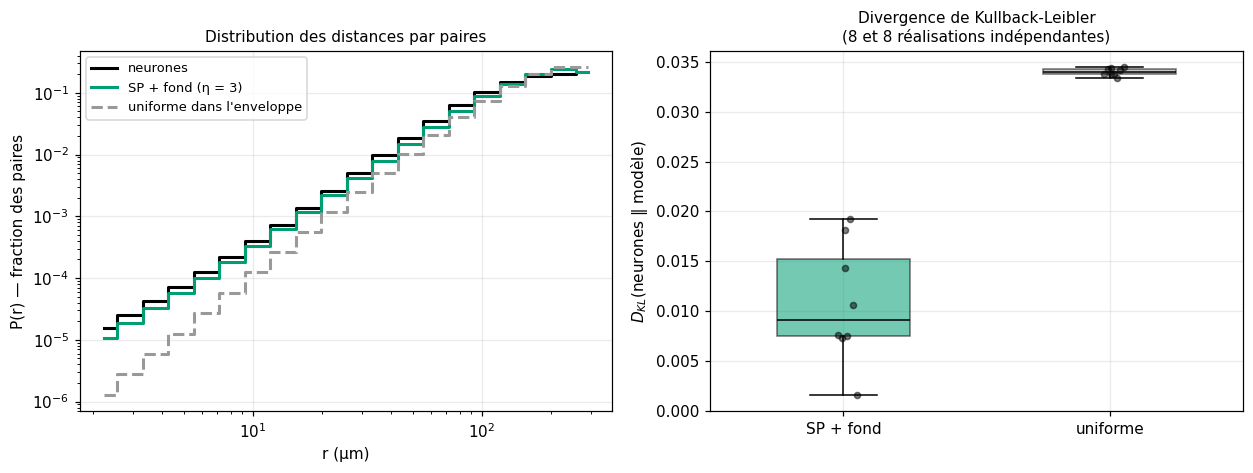

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

ax = axes[0]
ax.step(r_c/NM, P_data, where="mid", color=C["data"], lw=2, label="neurones")
ax.step(r_c/NM, KL["H_mod"].mean(axis=0), where="mid", color=C["mix"], lw=2,
        label=f"SP + fond (η = {eta_star})")
ax.step(r_c/NM, KL["H_uni"].mean(axis=0), where="mid", color=C["random"], lw=2,
        ls="--", label="uniforme dans l'enveloppe")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (µm)"); ax.set_ylabel("P(r) — fraction des paires")
ax.set_title("Distribution des distances par paires", fontsize=10)
ax.legend(fontsize=8.5)

ax = axes[1]
bp = ax.boxplot([KL["mod"], KL["uni"]], labels=["SP + fond", "uniforme"],
                widths=.5, patch_artist=True, medianprops=dict(color="k"))
for patch, col in zip(bp["boxes"], [C["mix"], C["random"]]):
    patch.set_facecolor(col); patch.set_alpha(.55)
for x, v in zip([1, 2], [KL["mod"], KL["uni"]]):
    ax.plot(np.full(len(v), x) + np.random.default_rng(0).normal(0, .04, len(v)),
            v, "o", ms=4, color="k", alpha=.5)
ax.set_ylabel(r"$D_{KL}$(neurones $\Vert$ modèle)")
ax.set_title(f"Divergence de Kullback-Leibler\n"
             f"({N_KL} et {N_UNI} réalisations indépendantes)", fontsize=10)
fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_kl.pdf", bbox_inches="tight")
plt.show()

## 10. À quoi ça ressemble

Deux nuages qui ont la même 2PCF n'ont pas forcément la même tête. La 2PCF est
une statistique **isotrope et moyennée sur tout le domaine** : elle ignore où
sont les amas, leur forme, leur nombre. La figure suivante met les deux nuages
côte à côte, à nombre de points affichés identique, dans les trois projections
du notebook 05.

In [17]:
DATA = ROOT / "data" / "fly_neuron_net" / "neurons.zip"
gdf  = mtpc.load_points_3d(DATA)
X    = mtpc.coords_3d(gdf)
print(f"{len(X):,} neurones chargés  |  modèle : {len(MODEL):,} points"
      .replace(",", " "))

238 909 neurones chargés  |  modèle : 238 909 points


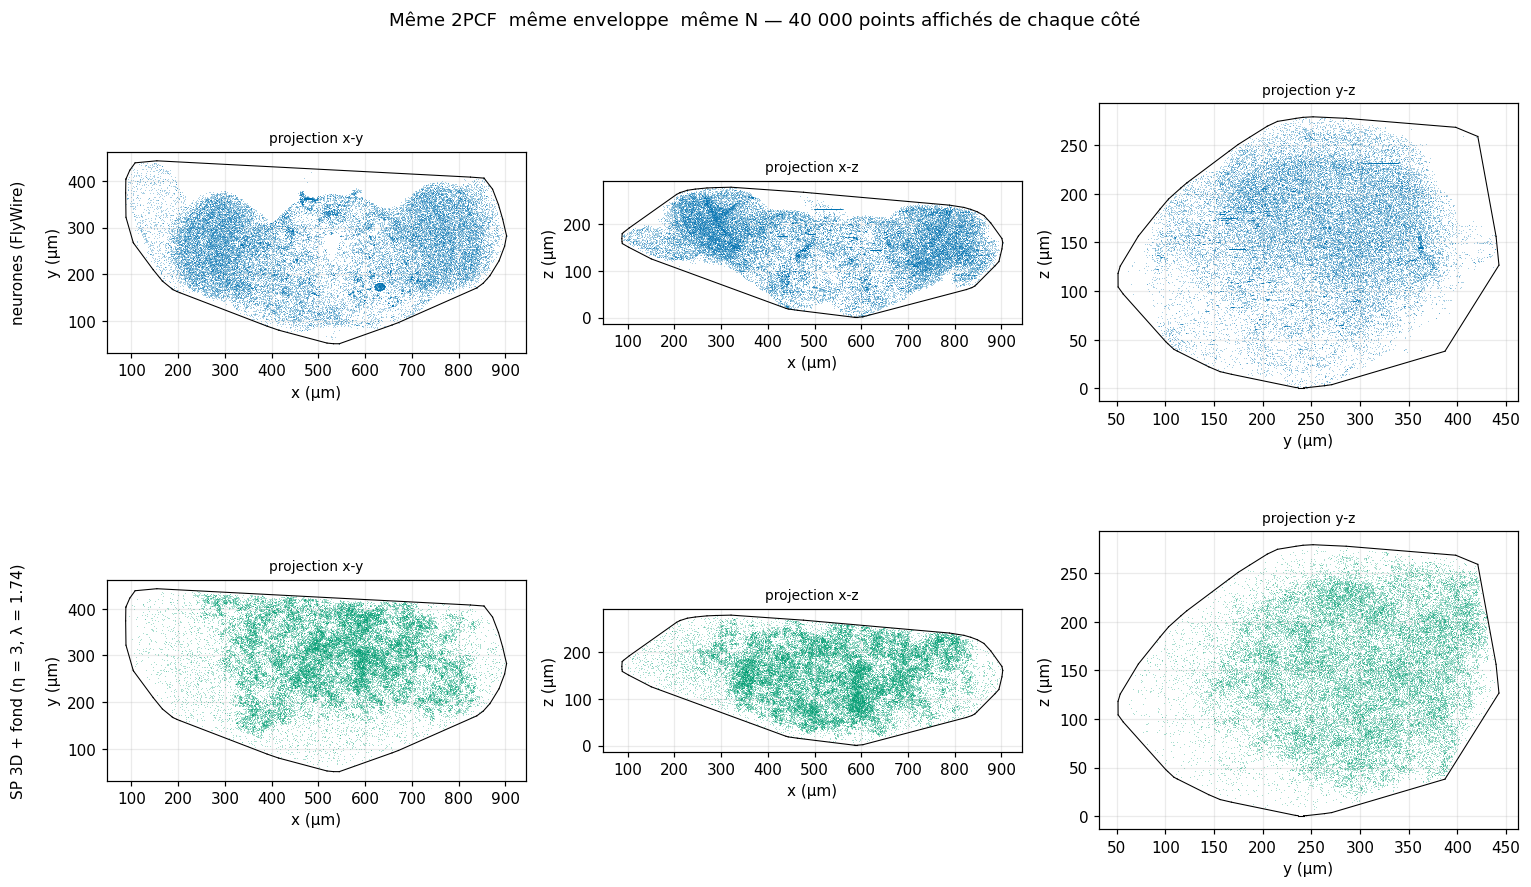

In [18]:
g_v = np.random.default_rng(SEED)
n_v = 40_000
sub_d = X[g_v.choice(len(X), n_v, replace=False)]
sub_m = MODEL[g_v.choice(len(MODEL), n_v, replace=False)]

fig, axes = plt.subplots(2, 3, figsize=(14, 8.4))
for row, (P, col, nom) in enumerate([(sub_d, C["fly"], "neurones (FlyWire)"),
                                     (sub_m, C["mix"], f"SP 3D + fond "
                                      f"(η = {eta_star}, λ = {FIN['lamb']:.2f})")]):
    for ax, (i, j), lbl in zip(axes[row], [(0, 1), (0, 2), (1, 2)],
                               ["x-y", "x-z", "y-z"]):
        ax.scatter(P[:, i]/NM, P[:, j]/NM, s=.4, alpha=.25, color=col, lw=0,
                   rasterized=True)
        for s in ConvexHull(hull.points[:, [i, j]]).simplices:
            ax.plot(hull.points[s, i]/NM, hull.points[s, j]/NM, color="k", lw=.7)
        ax.set_xlabel(f"{lbl[0]} (µm)"); ax.set_ylabel(f"{lbl[-1]} (µm)")
        ax.set_aspect("equal")
        if ax is axes[row][0]:
            ax.set_ylabel(f"{nom}\n\n{lbl[-1]} (µm)")
        ax.set_title(f"projection {lbl}", fontsize=9)
fig.suptitle("Même 2PCF, même enveloppe, même N — "
             f"{n_v:,}".replace(",", " ") + " points affichés de chaque côté")
fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_visuel.pdf", bbox_inches="tight", dpi=200)
plt.show()

Le verdict est net, et il n'était pas dans ξ : **le modèle ne remplit pas
l'enveloppe comme le cerveau**. Les neurones occupent tout le domaine avec deux
lobes symétriques et un creux central ; le SP se masse au centre et laisse le
pourtour vide. La raison est structurelle : l'arbre part d'**une seule** boule de
niveau 0 centrée sur le centroïde, et un enfant de niveau i est à moins de
R(λ^(−1) + … + λ^(−i)) < R/(λ−1) du centre — la densité du modèle décroît donc
radialement, alors que celle du cerveau ne le fait pas. Le rejet des points hors
enveloppe accentue encore l'effet, puisqu'il redonne leur chance aux tirages
courts.

Deux nuages peuvent donc partager γ à 7 % près, r₀ à 4 % près, et n'avoir ni le
même support ni la même silhouette. C'est la limite de fond d'une calibration par
la 2PCF seule, et c'est ce que le § 11 chiffre.

## 11. Ce que le modèle ne reproduit pas

Trois écarts, mesurés plutôt que constatés à l'œil. Aucun n'est un défaut de
calibration : ce sont des propriétés que le Soneira-Peebles **ne contient pas**.

1. **Pas de taille de cellule.** La distribution des distances au plus proche
   voisin des neurones a un **mode net vers 3.6 µm** — l'encombrement typique
   d'un noyau, que deux cellules ne peuvent pas s'interpénétrer — et une queue
   jusqu'à zéro qui vient des **13 321 positions dupliquées** du jeu FlyWire
   (5.6 %, déjà signalées au notebook 05). Le SP tire ses enfants dans une boule
   sans aucune contrainte de recouvrement : sa distribution est unimodale,
   décalée vers 2.1 µm, et traîne jusqu'à 20 µm à cause du fond uniforme. Aucune
   de ces deux formes n'est dans ξ, dont le premier bin est déjà à 2.2 µm et qui
   compte des **paires**, pas des voisins.
2. **Les amas ne sont pas au bon endroit.** ξ ne contraint que des *statistiques
   de distances* ; le modèle place ses amas où le tirage les met. On le quantifie
   par la distance de chaque point du modèle au neurone réel le plus proche,
   comparée à celle d'un catalogue uniforme — et c'est l'écart le plus brutal du
   notebook.
3. **Pas de symétrie bilatérale.** Le cerveau de la drosophile a deux
   hémisphères ; le profil marginal en x des neurones est bimodal. Un SP est
   isotrope autour de son centre : il ne peut pas produire deux lobes, sauf par
   accident de tirage.

In [19]:
g_l   = np.random.default_rng(SEED + 3)
n_l   = 60_000
i_d   = g_l.choice(len(X), n_l, replace=False)
i_m   = g_l.choice(len(MODEL), n_l, replace=False)
U_l   = mtpc.sample_in_hull(hull, n_l, g_l)

nn = {}
for nom, P in [("neurones", X[i_d]), ("SP + fond", MODEL[i_m]), ("uniforme", U_l)]:
    nn[nom] = cKDTree(P).query(P, k=2, workers=-1)[0][:, 1]

T_data = cKDTree(X)
d_mod  = T_data.query(MODEL[i_m], workers=-1)[0]
d_uni  = T_data.query(U_l,        workers=-1)[0]
SEUIL  = 10 * NM
frac_mod = float((d_mod > SEUIL).mean())
frac_uni = float((d_uni > SEUIL).mean())

print(f"positions dupliquées dans les données : "
      f"{int(pd.DataFrame(X).duplicated().sum()):,} "
      f"({100*pd.DataFrame(X).duplicated().mean():.1f} %)\n".replace(",", " "))
print(f"{'':<12}{'d_ppv médiane (µm)':>21}{'mode (µm)':>12}{'1er centile (µm)':>19}")
be_m = np.logspace(np.log10(.05*NM), np.log10(30*NM), 60)
c_m  = np.sqrt(be_m[:-1] * be_m[1:])
for nom, v in nn.items():
    mode = c_m[np.histogram(v, bins=be_m)[0].argmax()]
    print(f"{nom:<12}{np.median(v)/NM:>21.2f}{mode/NM:>12.2f}"
          f"{np.percentile(v, 1)/NM:>19.3f}")
print(f"\n(le sous-échantillonnage à {n_l:,} points dilate ces distances d'un "
      f"facteur ~({len(X)/n_l:.1f})^(1/3) = {(len(X)/n_l)**(1/3):.2f} ; "
      f"seule la comparaison entre colonnes compte)".replace(",", " "))
print(f"\npoints à plus de {SEUIL/NM:.0f} µm de tout neurone réel : "
      f"modèle {100*frac_mod:.1f} %  |  uniforme {100*frac_uni:.1f} %")
print(f"distance médiane au neurone réel le plus proche : "
      f"modèle {np.median(d_mod)/NM:.2f} µm  |  uniforme {np.median(d_uni)/NM:.2f} µm")

positions dupliquées dans les données : 13 321 (5.6 %)

               d_ppv médiane (µm)   mode (µm)   1er centile (µm)
neurones                     3.11        3.62              0.000
SP + fond                    2.14        2.11              0.364
uniforme                     4.79        5.59              1.166

(le sous-échantillonnage à 60 000 points dilate ces distances d'un facteur ~(4.0)^(1/3) = 1.58 ; seule la comparaison entre colonnes compte)

points à plus de 10 µm de tout neurone réel : modèle 30.0 %  |  uniforme 27.8 %
distance médiane au neurone réel le plus proche : modèle 5.35 µm  |  uniforme 4.95 µm


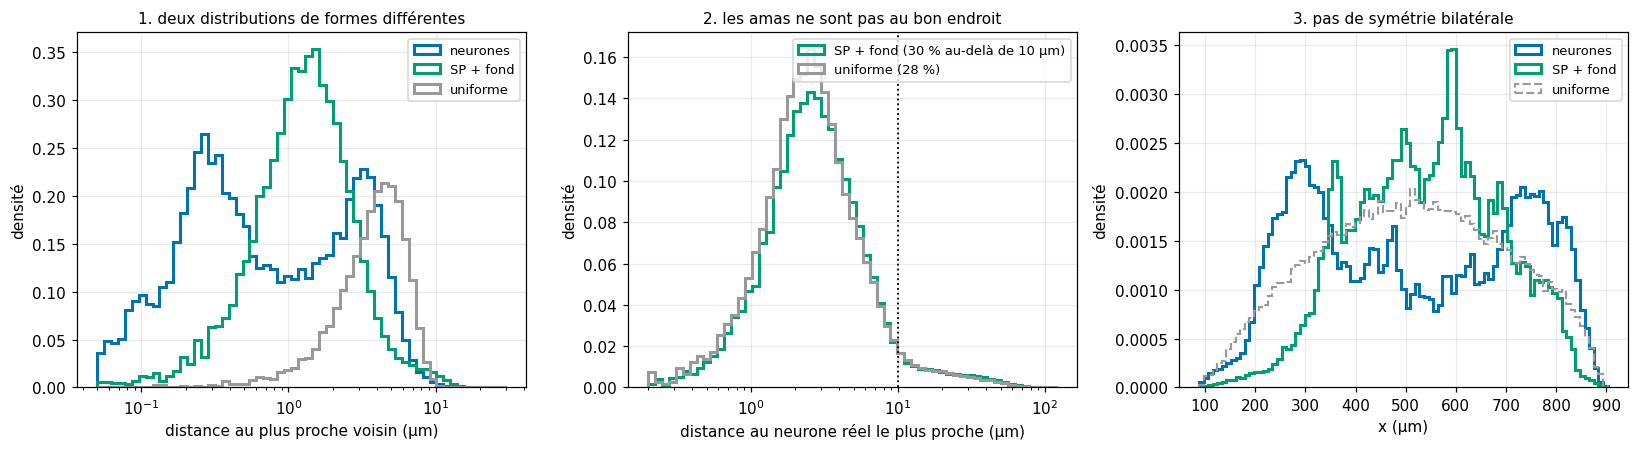

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
be = np.logspace(np.log10(.05), np.log10(30), 60)
for (nom, v), col in zip(nn.items(), [C["fly"], C["mix"], C["random"]]):
    ax.hist(v/NM, bins=be, histtype="step", lw=2, density=True, color=col, label=nom)
ax.set_xscale("log"); ax.set_xlabel("distance au plus proche voisin (µm)")
ax.set_ylabel("densité"); ax.legend(fontsize=8.5)
ax.set_title("1. deux distributions de formes différentes", fontsize=10)

ax = axes[1]
be2 = np.logspace(np.log10(.2), np.log10(120), 60)
ax.hist(d_mod/NM, bins=be2, histtype="step", lw=2, density=True, color=C["mix"],
        label=f"SP + fond ({100*frac_mod:.0f} % au-delà de 10 µm)")
ax.hist(d_uni/NM, bins=be2, histtype="step", lw=2, density=True, color=C["random"],
        label=f"uniforme ({100*frac_uni:.0f} %)")
ax.axvline(SEUIL/NM, color="k", ls=":", lw=1.2)
ax.set_xscale("log"); ax.set_xlabel("distance au neurone réel le plus proche (µm)")
ax.set_ylabel("densité"); ax.legend(fontsize=8.5)
ax.set_title("2. les amas ne sont pas au bon endroit", fontsize=10)

ax = axes[2]
bx = np.linspace(X[:, 0].min()/NM, X[:, 0].max()/NM, 90)
ax.hist(X[:, 0]/NM, bins=bx, histtype="step", lw=2, density=True, color=C["fly"],
        label="neurones")
ax.hist(MODEL[:, 0]/NM, bins=bx, histtype="step", lw=2, density=True, color=C["mix"],
        label="SP + fond")
ax.hist(U_l[:, 0]/NM, bins=bx, histtype="step", lw=1.4, ls="--", density=True,
        color=C["random"], label="uniforme")
ax.set_xlabel("x (µm)"); ax.set_ylabel("densité"); ax.legend(fontsize=8.5)
ax.set_title("3. pas de symétrie bilatérale", fontsize=10)

fig.tight_layout()
fig.savefig(ROOT / "out" / "05bis_sp3d_limites.pdf", bbox_inches="tight")
plt.show()

## 12. Sauvegarde

Même convention que le notebook 05 : un pickle avec tout ce qui sert en aval
(les ξ par réalisation, le modèle retenu, le balayage complet), et deux CSV
lisibles à l'œil.

In [21]:
out_dir = ROOT / "out" / "fly"
out_dir.mkdir(parents=True, exist_ok=True)

scan_tab = pd.DataFrame([
    dict(eta=eta, essai=t, lamb=SCAN[(eta, t)]["lamb"], L=SCAN[(eta, t)]["L"],
         n_leaves=SCAN[(eta, t)]["n_leaves"],
         r_bot_um=SCAN[(eta, t)]["r_bot"]/NM,
         gamma_sp=SCAN[(eta, t)]["gamma_sp"], rho=SCAN[(eta, t)]["rho"],
         frac=SCAN[(eta, t)]["frac"], gamma_mix=SCAN[(eta, t)]["gamma_mx"],
         cost_log=SCAN[(eta, t)]["cost"], cost_eucl=SCAN[(eta, t)]["cost_eucl"])
    for eta in l_cluster for t in range(N_TRY)])

xi_tab = pd.DataFrame({
    "r_nm": r_c, "r_um": r_c/NM, "in_fit_window": WIN,
    "xi_data": xi_data, "xi_data_std": err_data,
    "xi_sp": FIN["xi_sp"], "xi_sp_std": FIN["xi_sp_std"],
    "xi_mix": FIN["xi"], "xi_mix_std": FIN["xi_std"],
    "P_data": P_data, "P_mix": KL["H_mod"].mean(axis=0),
    "P_uniform": KL["H_uni"].mean(axis=0)})

d_save = {
    "r_edges": r_edges, "r_centers": r_c,
    "xi": FIN["l_xi"],                       # (8, nbins) — même forme qu'au 05
    "xi_data": d["xi"], "xi_sp": FIN["xi_sp"],
    "fit_SP": (fit_mx["gamma"], fit_mx["r0"]),
    "fit_data": (gamma_d, r0_d),
    "model_points": MODEL,
    "sp_params": dict(eta=int(eta_star), lamb=FIN["lamb"], L=int(FIN["L"]),
                      R_ref=R_ref, center=cen, radial="uniform",
                      n_leaves=int(FIN["n_leaves"]), rho=FIN["rho"],
                      frac=FIN["frac"], N_sp=int(FIN["N_sp"]),
                      N_rd=int(FIN["N_rd"]), D=3 - gamma_d),
    "scan": scan_tab.to_dict("list"),
    "kl": dict(model=KL["mod"], uniform=KL["uni"]),
    "number_points": len(MODEL), "dim": 3,
    "hull_points": d["hull_points"],
    "params": dict(prm, seed=SEED, fit_hi=FIT_HI, N_TRY=N_TRY,
                   source=str(PKL.name)),
}
pkl_out = out_dir / f"fly_sp3d_{eta_star}_{FIN['L']}_{N_TRY}_{prm['nbins']}"
slp.save_results(pkl_out, d_save)
print("->", pkl_out)

scan_tab.to_csv(ROOT / "out" / "05bis_fly_sp3d_scan.csv", index=False)
xi_tab.to_csv(ROOT / "out" / "05bis_fly_sp3d.csv", index=False)
print("->", ROOT / "out" / "05bis_fly_sp3d_scan.csv")
print("->", ROOT / "out" / "05bis_fly_sp3d.csv")

resume = pd.DataFrame([
    dict(quantite="γ", donnees=gamma_d, modele=fit_mx["gamma"],
         fractale_seule=fit_sp["gamma"]),
    dict(quantite="r0 (µm)", donnees=r0_d/NM, modele=fit_mx["r0"]/NM,
         fractale_seule=fit_sp["r0"]/NM),
    dict(quantite="D = 3 - γ", donnees=3 - gamma_d, modele=3 - fit_mx["gamma"],
         fractale_seule=3 - fit_sp["gamma"]),
    dict(quantite="ξ(2.2 µm)", donnees=xi_data[0], modele=FIN["xi"][0],
         fractale_seule=FIN["xi_sp"][0]),
    dict(quantite="D_KL vs neurones", donnees=0.0, modele=KL["mod"].mean(),
         fractale_seule=np.nan),
])
resume.to_csv(ROOT / "out" / "05bis_fly_sp3d_summary.csv", index=False)
print()
print(resume.round(3).to_string(index=False))

-> out/fly/fly_sp3d_3_12_3_21
-> out/05bis_fly_sp3d_scan.csv
-> out/05bis_fly_sp3d.csv

        quantite  donnees  modele  fractale_seule
               γ    1.022   0.955           0.949
         r0 (µm)   19.522  20.232          31.460
       D = 3 - γ    1.978   2.045           2.051
       ξ(2.2 µm)   11.050   8.054          12.042
D_KL vs neurones    0.000   0.011             NaN


## 13. Bilan

**Le modèle demandé existe et il tient.** En rendant au Soneira-Peebles sa
dimension d'origine — λ = η^(1/(3−γ)) et des enfants tirés dans des **boules** —
on obtient un nuage de 238 909 points dans l'enveloppe convexe du cerveau dont
la 2PCF, mesurée avec **exactement** l'estimateur, le domaine, les bins et le
nombre de points du notebook 05, donne γ = 0.955 ± 0.009 contre 1.022 ± 0.036
pour les neurones, et r₀ = 20.2 µm contre 19.5 µm. L'écart en pente est de
1.8 σ de la barre des données ; l'écart relatif sur ξ lui-même est de 8 % en
médiane sur les 17 bins ajustés. Le modèle retenu : **η = 3, λ = 1.743, L = 12**,
soit 531 441 feuilles, dont on tire 193 783 points (f = √ρ = 0.81) complétés par
45 126 points de fond uniforme.

**Les trois corrections annoncées par le notebook 05 étaient nécessaires, et
elles ne font pas la même chose.**

| Correction | Ce qu'elle change |
|---|---|
| λ = η^(1/(3−γ)) au lieu de η^(1/(2−γ)) | la **dimension** : D = 1.978 au lieu de 0.978 — la formule 2D donne un objet filiforme, pas une fractale de ℝ³ |
| enfants dans la **boule**, r = R·u^(1/3) | l'**amplitude** : la loi radiale du code 2D (`r = R·u`) laisse D inchangée (1.974) mais multiplie ξ(2.2 µm) par 2.2 — elle concentre les enfants au centre de chaque amas |
| rejet enfant par enfant | la **faisabilité** : la boule de niveau 0 fait 12.2 fois le volume de l'enveloppe, 92 % des enfants du niveau 1 tombent dehors ; relancer l'arbre entier (`check_inside`) ne se termine pas |

**η n'est pas identifiable par ξ, et c'est un résultat, pas un échec.** Les cinq
candidats de la silhouette partagent la même D par construction : ils ne
diffèrent que par la lacunarité, que ξ ne mesure pas. L'écart de coût entre le
meilleur (η = 3, 0.064) et le pire (η = 6, 0.208) est de 0.144, pour une
dispersion **d'un arbre à l'autre à η fixé** de 0.071 en moyenne : la moitié du
classement est du bruit de tirage. Aux deux bouts, le modèle cesse d'être
reproductible — à η = 2 la pente varie de 0.82 à 1.46 d'un arbre à l'autre, à
η = 6 le coût va de 0.065 à 0.469 — et c'est η = 3 qui est à la fois le plus bas
et le plus serré (0.064 ± 0.013). On choisit donc η pour la **stabilité**, pas
pour l'ajustement.

**Une seconde métrique confirme, avec un gain modeste.** La divergence de
Kullback-Leibler entre distributions de distances par paires, que la calibration
n'a pas vue, vaut 0.0108 ± 0.0056 pour le modèle contre 0.0340 ± 0.0003 pour le
catalogue uniforme : le SP explique **68 %** de la divergence au modèle nul.
C'est réel, et c'est loin de tout.

**Ce qu'il ne faut pas lui demander.** Trois écarts mesurés au § 11 :
la distribution des plus proches voisins a un mode à 2.1 µm là où les neurones
en ont un à 3.6 µm (le modèle ignore qu'une cellule a une taille) ; **30.0 %**
des points du modèle sont à plus de 10 µm de tout neurone réel, contre 27.8 %
pour un catalogue uniforme — autrement dit, pour *localiser* les neurones, le
modèle ne fait **pas mieux que le hasard** ; et le profil en x reste unimodal là
où le cerveau est bilatéral. Le § 10 ajoute le plus visible des trois : le SP,
parti d'une seule boule de niveau 0, a une densité qui **décroît radialement**,
si bien qu'il se masse au centre de l'enveloppe pendant que les neurones
l'occupent entièrement. La 2PCF est une statistique isotrope et moyennée :
reproduire ξ, c'est reproduire une loi d'échelle, pas une anatomie.

**Où ça mène.** Le notebook [`06`](06_powergrid_sp_joule.ipynb) a fait la
démonstration sur le réseau électrique : remplacer la géographie posée à la main
d'un modèle de croissance par le SP mixte calibré, et regarder si la
**dynamique** survit. Le pendant ici serait de brancher ce nuage 3D sur un
modèle de câblage et de comparer les observables du connectome — et la mesure du
§ 11 dit d'avance quel genre d'observable pourra tenir : celles qui ne dépendent
que des **distances**, pas celles qui dépendent de **où** sont les amas.